# Exploratory data analysis: public procurement awards 2019-2022

**Data:** the clean tables built by `python -m procurement.pipeline`: 3,557,158 EU contract award records (TED, 33 countries) and 142,870 World Bank contract-supplier rows, 2019-2022.

**How to read this notebook:** every finding is written directly below the output it comes from, and every number in a finding is printed in that output.

**Key findings** (section numbers in brackets)

1. **The single-bid label is usable:** 97.7% of 2,879,742 awarded contracts have a valid number of offers, and 32.3% of them received a single offer (4).
2. **Missing labels are structural:** of the raw rows without an offer count, 46.9% are lot rows with no award section and 48.5% are lots never awarded; only 0.2% are awarded contracts that omit it (3).
3. **Procedure type matters most:** non-competitive procedures 73.0% single-bid vs 30.6% for competitive ones (5.2).
4. **Large differences by country, sector, contract type and size:** Slovenia 60.3% vs Iceland 6.4%; laboratory equipment 51.9% vs construction work 13.6%; supplies 37.5% vs works 13.5%; under EUR 10k 38.0% vs EUR 10M+ 13.9% (5).
5. **9.04% of award values are below EUR 100**, mostly in Germany (39.5% of German awards) and the Netherlands (44.3%) (6).
6. **Name standardisation removes 33.3% of distinct winner names;** 124 spellings become `siemens healthcare` (7).
7. **Correcting joint-venture repeats removes USD 4.42 bn** (7.7%) from World Bank totals (8).
8. **672 companies** won both EU tenders and World Bank contracts (9).

All rates are descriptive associations. A high single-bid rate is a risk indicator worth investigating, not evidence of wrongdoing.

## 0. Setup

Run `python -m procurement.pipeline` first: it builds the database this notebook reads. The connection is read-only. The SQL in this notebook is exploratory; the cleaning rules themselves live in `sql/clean/`. Each query returns a pandas DataFrame, and the pandas equivalent of the standard checks is noted in the code comments.

In [1]:
# Make the project package importable whether the notebook runs from the
# project root (VS Code default) or from the notebooks/ folder.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
from IPython.display import display

from procurement import config

# Read-only connection: the notebook can never change the database.
connection = duckdb.connect(str(config.DATABASE_PATH), read_only=True)


def query(sql):
    """Run SQL against the project database and return a pandas DataFrame."""
    return connection.sql(sql).df()


def as_percent(frame, columns, decimals=1):
    """Return a copy where the given share columns are shown as percentages (0.184 -> '18.4%')."""
    frame = frame.copy()
    for column in columns:
        frame[column] = frame[column].map(lambda value: "" if pd.isna(value) else f"{value:.{decimals}%}")
    return frame


# One chart style for the whole notebook: one bar colour, a grey reference
# line, light grid behind the bars, a value label on every bar.
BAR_COLOUR = "#2a78d6"
REFERENCE_COLOUR = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e0",
    "axes.edgecolor": "#b5b4ad",
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
    "font.size": 9,
})
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 60
pd.options.display.width = 250


def bar_chart(frame, label_column, value_column, title, xlabel,
              reference=None, reference_label=None, percent=False):
    """Horizontal bar chart, largest at the top, value printed at each bar end."""
    frame = frame.sort_values(value_column)
    height = max(2.2, 0.32 * len(frame) + 0.8)
    figure, axis = plt.subplots(figsize=(8, height))
    bars = axis.barh(frame[label_column].astype(str), frame[value_column], color=BAR_COLOUR, height=0.7)
    text_format = "{:.1%}" if percent else "{:,.0f}"
    for bar, value in zip(bars, frame[value_column]):
        axis.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, " " + text_format.format(value),
                  va="center", fontsize=8, color="#0b0b0b")
    if reference is not None:
        axis.axvline(reference, color=REFERENCE_COLOUR, linestyle="--", linewidth=1,
                     label=f"{reference_label} ({reference:.1%})")
        axis.legend(loc="lower right", frameon=False, fontsize=8)
    if percent:
        axis.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
    axis.margins(x=0.12)
    axis.set_title(title, loc="left")
    axis.set_xlabel(xlabel)
    axis.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()

## 1. First look at the data

### 1.1 Size of each table

In [3]:
# pandas equivalent: df.shape
shape = query("""
    SELECT 'raw_ted_awards' AS table_name,
           (SELECT COUNT(*) FROM raw_ted_awards) AS rows,
           (SELECT COUNT(*) FROM (DESCRIBE raw_ted_awards)) AS columns
    UNION ALL
    SELECT 'ted_awards (clean)',
           (SELECT COUNT(*) FROM ted_awards),
           (SELECT COUNT(*) FROM (DESCRIBE ted_awards))
    UNION ALL
    SELECT 'raw_world_bank_awards',
           (SELECT COUNT(*) FROM raw_world_bank_awards),
           (SELECT COUNT(*) FROM (DESCRIBE raw_world_bank_awards))
    UNION ALL
    SELECT 'world_bank_awards (clean)',
           (SELECT COUNT(*) FROM world_bank_awards),
           (SELECT COUNT(*) FROM (DESCRIBE world_bank_awards))
""")
shape

,table_name,rows,columns
0,raw_ted_awards,4295572,76
1,ted_awards (clean),3557158,40
2,raw_world_bank_awards,142870,22
3,world_bank_awards (clean),142870,24


**Finding.** Cleaning reduced TED from 4,295,572 raw rows and 76 text columns to 3,557,158 awards and 40 typed columns: one row per contract award, with only the columns the analysis needs plus derived ones (labels, flags, standardised names). The World Bank table keeps all 142,870 rows (one per supplier on a contract) and grows from 22 to 24 columns with the cleaning additions.

### 1.2 TED clean table: columns and types

In [4]:
# pandas equivalent: df.dtypes  (or df.info())
query("SELECT column_name, column_type FROM (DESCRIBE ted_awards)")

,column_name,column_type
0,award_id,BIGINT
1,notice_id,BIGINT
2,notice_year,INTEGER
3,publication_date,DATE
4,award_date,DATE
5,buyer_country,VARCHAR
6,buyer_name,VARCHAR
7,buyer_type_code,VARCHAR
8,buyer_main_activity,VARCHAR
9,contract_type_code,VARCHAR


### 1.3 First and last rows

In [5]:
# pandas equivalent: df.head()
# Winner names are left out of printed samples: some winners are individual people.
SAMPLE_COLUMNS = "* EXCLUDE (winner_name, winner_name_std)"
query(f"SELECT {SAMPLE_COLUMNS} FROM ted_awards LIMIT 5")

,award_id,notice_id,notice_year,publication_date,award_date,buyer_country,buyer_name,buyer_type_code,buyer_main_activity,contract_type_code,procedure_code,award_criterion_code,is_framework_agreement,is_eu_funded,is_gpa_covered,used_electronic_auction,lots_in_notice,cpv_code,cpv_division,estimated_value_eur,award_value_eur,number_offers_raw,number_offers_from_sme,winner_count,winner_country,winner_is_sme,title,source_file,award_status,number_offers,is_single_bid,award_value_quality,contract_type,procedure_type,is_competitive_procedure,award_criterion,buyer_type,cpv_division_name
0,13955346,202238848,2022,2022-01-19,2021-11-15,BE,Artevelde Hogeschool---Hogeschool Gent---Unive...,6,Education,S,OPE,M,True,False,False,False,23,72000000,72,NaN,"200,000.00",3,<NA>,1,BE,False,None,ted-contract-award-notices-2022.zip,awarded,3,0,plausible,Services,Open,True,Most economically advantageous tender,Body governed by public law,"IT services: consulting, software development,..."
1,13955384,202238855,2022,2022-01-19,2021-04-02,IT,RISORSE AMBIENTE PALERMO S.p.A.,8,Environment,S,OPE,L,False,False,False,False,4,50114100,50,"50,515.68","50,515.68",4,<NA>,1,IT,True,LOTTO N.3 -SERVIZIO DI RIPARAZIONE SU N.17 AUT...,ted-contract-award-notices-2022.zip,awarded,4,0,plausible,Services,Open,True,Lowest price,Other,Repair and maintenance services
2,13955471,202238900,2022,2022-01-19,NaT,SI,MINISTRSTVO ZA NOTRANJE ZADEVE,1,General public\services,S,OPE,M,False,False,False,False,36,79500000,79,NaN,NaN,<NA>,<NA>,0,None,<NA>,Pisno prevajanje in tolmačenje iz moldavskega ...,ted-contract-award-notices-2022.zip,not_awarded_unsuccessful,<NA>,<NA>,missing,Services,Open,True,Most economically advantageous tender,National authority,"Business services: law, marketing, consulting,..."
3,13955496,202238904,2022,2022-01-19,2021-12-31,SI,UNIVERZA NA PRIMORSKEM UNIVERSITA DEL LITORALE...,6,Education,S,OPE,L,False,False,False,False,6,50000000,50,NaN,"1,884.00",1,1,1,SI,True,SKLOP 3: servis in vzdrževanje hladilno-prezra...,ted-contract-award-notices-2022.zip,awarded,1,1,plausible,Services,Open,True,Lowest price,Body governed by public law,Repair and maintenance services
4,13955503,202238908,2022,2022-01-19,2022-01-11,SI,ZDRAVSTVENI DOM LJUBLJANA,6,Health,S,OPE,L,False,False,False,False,1,79995100,79,"531,000.00","456,000.00",2,2,1,SI,True,None,ted-contract-award-notices-2022.zip,awarded,2,0,plausible,Services,Open,True,Lowest price,Body governed by public law,"Business services: law, marketing, consulting,..."


In [6]:
# pandas equivalent: df.tail()
ted_rows = connection.sql("SELECT COUNT(*) FROM ted_awards").fetchone()[0]
query(f"SELECT {SAMPLE_COLUMNS} FROM ted_awards LIMIT 5 OFFSET {ted_rows - 5}")

,award_id,notice_id,notice_year,publication_date,award_date,buyer_country,buyer_name,buyer_type_code,buyer_main_activity,contract_type_code,procedure_code,award_criterion_code,is_framework_agreement,is_eu_funded,is_gpa_covered,used_electronic_auction,lots_in_notice,cpv_code,cpv_division,estimated_value_eur,award_value_eur,number_offers_raw,number_offers_from_sme,winner_count,winner_country,winner_is_sme,title,source_file,award_status,number_offers,is_single_bid,award_value_quality,contract_type,procedure_type,is_competitive_procedure,award_criterion,buyer_type,cpv_division_name
0,15385502,2022735030,2022,2022-12-27,NaT,RO,Penitenciar Spital Bucuresti Jilava,6,Public Order and Safety,U,OPE,L,False,False,False,False,42,33690000,33,NaN,NaN,<NA>,<NA>,0,None,<NA>,None,ted-contract-award-notices-2022.zip,not_awarded_unsuccessful,<NA>,<NA>,missing,Supplies,Open,True,Lowest price,Body governed by public law,"Medical equipment, pharmaceuticals and persona..."
1,15385505,2022735033,2022,2022-12-27,NaT,LT,Lietuvos sveikatos mokslų universiteto ligonin...,6,Health,W,OPE,L,False,False,True,False,1,45000000,45,NaN,NaN,<NA>,<NA>,0,None,<NA>,Kauno klinikų gyvenamojo pastato 26N1p (Unik. ...,ted-contract-award-notices-2022.zip,not_awarded_discontinued,<NA>,<NA>,missing,Works,Open,True,Lowest price,Body governed by public law,Construction work
2,15385511,2022735041,2022,2022-12-27,2022-12-27,DE,Landesbetrieb Straßenwesen Brandenburg,3,Other,U,OPE,L,False,False,False,False,2,34000000,34,NaN,0.01,1,0,1,DE,False,"2 Pkw-Hochdachkombi, 2 Sitze (E-Fahrzeuge)",ted-contract-award-notices-2022.zip,awarded,1,1,too_low,Supplies,Open,True,Lowest price,Regional or local authority,Transport equipment and auxiliary products to ...
3,15385514,2022735045,2022,2022-12-27,NaT,PL,PGE Energia Ciepła S.A.,4,Electricity,S,OPE,L,False,False,True,False,1,50530000,50,NaN,NaN,<NA>,<NA>,0,None,<NA>,Świadczenie kompleksowych usług w zakresie pra...,ted-contract-award-notices-2022.zip,not_awarded_unsuccessful,<NA>,<NA>,missing,Services,Open,True,Lowest price,Utilities,Repair and maintenance services
4,15385534,2022735058,2022,2022-12-27,2022-12-22,RO,"Universitatea ""Alexandru Ioan Cuza"" Iasi",6,Education,U,OPE,L,False,True,False,False,10,38300000,38,"81,915.90","81,885.60",1,1,1,RO,True,Contract furnizare sonar + acvarii (produse lo...,ted-contract-award-notices-2022.zip,awarded,1,1,plausible,Supplies,Open,True,Lowest price,Body governed by public law,"Laboratory, optical and precision equipment"


### 1.4 Summary statistics for every column

In [7]:
# pandas equivalent: df.describe(include="all") plus df.isna().mean()
# SUMMARIZE computes, for every column: min, max, approximate number of unique
# values, mean, standard deviation, quartiles and the percentage of missing values.
# Name columns are excluded: their alphabetical min/max could print a person's name.
ted_summary = query("SUMMARIZE SELECT * EXCLUDE (winner_name, winner_name_std) FROM ted_awards")
ted_summary[["column_name", "column_type", "min", "max", "approx_unique",
             "avg", "q25", "q50", "q75", "null_percentage"]]

,column_name,column_type,min,max,approx_unique,avg,q25,q50,q75,null_percentage
0,award_id,BIGINT,10169728,15385540,3753999,12600977.45246992,11208898,12533244,13930528,0.00
1,notice_id,BIGINT,20192,2022735066,1025373,1692468686.769955,2019316219,2020471948,2021599703,0.00
2,notice_year,INTEGER,2019,2022,4,2020.574418960305,2020,2021,2022,0.00
3,publication_date,DATE,2018-12-17,2022-12-27,1469,2021-01-23 01:22:42.132129,2020-01-30,2021-02-03,2022-01-14,0.00
4,award_date,DATE,1970-01-01,2022-12-27,2979,2020-11-16 15:56:01.011133,2019-11-20,2020-12-03,2021-11-21,20.20
5,buyer_country,VARCHAR,AT,UK,39,None,None,None,None,0.00
6,buyer_name,VARCHAR,\tOffizielle Bezeichnung: LVR-Dezernat Gebäude...,„Южноцентрално предприятие“ ДП — гр. Смолян,173043,None,None,None,None,0.00
7,buyer_type_code,VARCHAR,1,Z,10,None,None,None,None,0.00
8,buyer_main_activity,VARCHAR,Airport-related activities,Water,46,None,None,None,None,0.00
9,contract_type_code,VARCHAR,S,W,3,None,None,None,None,0.00


In [8]:
# Checks suggested by the summary above (min/max values that look wrong).
query("""
    SELECT 'TED award_date before 2015' AS check_name, COUNT(*) AS rows
    FROM ted_awards WHERE award_date < DATE '2015-01-01'
    UNION ALL
    SELECT 'TED award value of EUR 1 billion or more', COUNT(*)
    FROM ted_awards WHERE award_value_eur >= 1e9
    UNION ALL
    SELECT 'TED winner_country not a two-letter code', COUNT(*)
    FROM ted_awards WHERE winner_country IS NOT NULL AND NOT REGEXP_MATCHES(winner_country, '^[A-Z]{2}$')
    UNION ALL
    SELECT 'TED buyer or winner name starting with a tab or space', COUNT(*)
    FROM ted_awards WHERE REGEXP_MATCHES(buyer_name, '^\s') OR REGEXP_MATCHES(winner_name, '^\s')
    UNION ALL
    SELECT 'World Bank supplier_country written as the text "null"', COUNT(*)
    FROM world_bank_awards WHERE supplier_country = 'null'
""")

<>:13: SyntaxWarning: invalid escape sequence '\s'
<>:13: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1046/3415113051.py:13: SyntaxWarning: invalid escape sequence '\s'
  FROM ted_awards WHERE REGEXP_MATCHES(buyer_name, '^\s') OR REGEXP_MATCHES(winner_name, '^\s')


,check_name,rows
0,TED award_date before 2015,505
1,TED award value of EUR 1 billion or more,1530
2,TED winner_country not a two-letter code,30
3,TED buyer or winner name starting with a tab o...,1393
4,World Bank supplier_country written as the tex...,43


**Findings from the summary statistics and the checks above.**
- **Ranges look right for the main fields:** `notice_year` 2019-2022, `publication_date` 2018-12-17 to 2022-12-27 (late-December 2018 dispatches published in 2019), `is_single_bid` mean 0.323 (= the 32.3% single-bid rate).
- **Extreme values are visible:** `award_value_eur` reaches EUR 11.4 trillion, which is impossible. The 1,530 values of EUR 1 billion or more are flagged, either `too_high` or `placeholder` (values made only of 9s, such as 999,999,999; see section 6). The mean value (EUR 214 million) is far above the median (q50), so values are heavily skewed (section 6).
- **Small data-entry problems remain:** 505 award dates before 2015 (the minimum, 1970-01-01, is a typical "empty date" placeholder), 30 winner countries that are not two-letter codes, 1,393 names starting with a tab or space, and 43 World Bank rows with the country written as the text "null". These are small counts; they are recorded here and handled where they matter (name standardisation already strips the spaces).
- `approx_unique` is an approximation (fast for millions of rows): for example it shows 39 for `buyer_country`, while the exact count in section 2 is 33.

### 1.5 Missing values per column

In [9]:
# pandas equivalent: df.isna().mean().sort_values(ascending=False)
ted_missing = ted_summary[["column_name", "null_percentage"]].copy()
ted_missing["missing_share"] = ted_missing["null_percentage"].astype(float) / 100
ted_missing = ted_missing.sort_values("missing_share", ascending=False)
as_percent(ted_missing[ted_missing["missing_share"] > 0][["column_name", "missing_share"]], ["missing_share"])

,column_name,missing_share
19,estimated_value_eur,59.2%
22,number_offers_from_sme,54.2%
20,award_value_eur,20.9%
29,number_offers,20.9%
30,is_single_bid,20.9%
21,number_offers_raw,20.8%
25,winner_is_sme,20.6%
4,award_date,20.2%
24,winner_country,20.1%
26,title,17.9%


**Finding.** About 20.9% of rows miss award-level fields (`number_offers`, `award_value_eur`, `winner_*`, `award_date`). These are mostly the records that were never awarded (15.4% unsuccessful + 3.7% discontinued, section 1.6), which have no winner or offers by definition. `estimated_value_eur` is missing for 59.2% of awards and `number_offers_from_sme` for 54.2%, so neither can be relied on as a model feature without care. Core descriptive fields (country, buyer, contract type, sector, dates) are complete.

### 1.6 Main categorical columns

In [10]:
# pandas equivalent: df["column"].value_counts(normalize=True)
for column in ["award_status", "contract_type", "procedure_type", "award_criterion", "buyer_type"]:
    counts = query(f"""
        SELECT {column}, COUNT(*) AS awards, COUNT(*) / SUM(COUNT(*)) OVER () AS share
        FROM ted_awards
        GROUP BY {column}
        ORDER BY awards DESC
    """)
    display(as_percent(counts, ["share"]))

,award_status,awards,share
0,awarded,2879742,81.0%
1,not_awarded_unsuccessful,547084,15.4%
2,not_awarded_discontinued,130332,3.7%


,contract_type,awards,share
0,Supplies,2084226,58.6%
1,Services,1194887,33.6%
2,Works,278045,7.8%


,procedure_type,awards,share
0,Open,3123946,87.8%
1,Negotiated with call for competition,166550,4.7%
2,Restricted,127196,3.6%
3,Negotiated without call for competition,87175,2.5%
4,Award without prior publication,39293,1.1%
5,None,7760,0.2%
6,Competitive dialogue,3721,0.1%
7,Innovative partnership,1517,0.0%


,award_criterion,awards,share
0,Lowest price,1806053,50.8%
1,Most economically advantageous tender,1494653,42.0%
2,None,256452,7.2%


,buyer_type,awards,share
0,Body governed by public law,1066695,30.0%
1,Other,966883,27.2%
2,Regional or local authority,746304,21.0%
3,National authority,362922,10.2%
4,Utilities,230357,6.5%
5,Regional or local agency,99732,2.8%
6,National agency,72796,2.0%
7,EU institution or agency,9558,0.3%
8,Not specified,1598,0.0%
9,Other international organisation,313,0.0%


**Finding.** 81.0% of records are awarded. Supplies dominate (58.6%), then services (33.6%) and works (7.8%). The open procedure is used for 87.8% of awards. Lowest price is the criterion for 50.8% and best value (MEAT) for 42.0% (7.2% missing). Bodies governed by public law (30.0%) and regional or local authorities (21.0%) are the largest buyer types.

### 1.7 World Bank clean table

In [11]:
query("SELECT column_name, column_type FROM (DESCRIBE world_bank_awards)")

,column_name,column_type
0,contract_id,VARCHAR
1,fiscal_year,INTEGER
2,signing_date,DATE
3,signing_year,INTEGER
4,region,VARCHAR
5,borrower_country,VARCHAR
6,borrower_country_code,VARCHAR
7,project_id,VARCHAR
8,project_name,VARCHAR
9,global_practice,VARCHAR


In [12]:
# head and tail; supplier names are companies or consultants, so they are left out here too
WB_SAMPLE_COLUMNS = "* EXCLUDE (supplier_name, supplier_name_std, supplier_id)"
wb_rows = connection.sql("SELECT COUNT(*) FROM world_bank_awards").fetchone()[0]
display(query(f"SELECT {WB_SAMPLE_COLUMNS} FROM world_bank_awards LIMIT 5"))
display(query(f"SELECT {WB_SAMPLE_COLUMNS} FROM world_bank_awards LIMIT 5 OFFSET {wb_rows - 5}"))

,contract_id,fiscal_year,signing_date,signing_year,region,borrower_country,borrower_country_code,project_id,project_name,global_practice,procurement_category,procurement_method,contract_description,supplier_country,supplier_country_code,amount_usd,review_type,source_file,suppliers_on_contract,amount_usd_for_totals,amount_quality
0,1778629,2020,2020-04-01,2020,Western and Central Africa,Senegal,SN,P166538,Senegal - Saint-Louis Emergency Recovery and R...,None,Consultant Services,Individual Consultant Selection,Recrutement d’un Expert en Génie Côtier spécia...,Senegal,SN,"158,277.53",Post,world_bank_contract_awards.csv,1,"158,277.53",plausible
1,1778631,2022,2022-05-18,2022,Latin America and Caribbean,Ecuador,EC,P157425,Transformation of the Tertiary Technical and T...,Education,Consultant Services,Individual Consultant Selection,Especialistas Desarrolladores de Software para...,Ecuador,EC,"10,404.44",Post,world_bank_contract_awards.csv,1,"10,404.44",plausible
2,1778638,2022,2021-09-17,2021,Europe and Central Asia,Kyrgyz Republic,KG,P151416,Urban Development Project,Public Admin;Energy & Extractives;Transportati...,Goods,Request for Quotations,Procurement of the automanipulator for the vod...,Kyrgyz Republic,KG,"45,638.96",Post,world_bank_contract_awards.csv,1,"45,638.96",plausible
3,1779099,2023,2022-12-12,2022,East Asia and Pacific,East Asia and Pacific,None,P170913,Southeast Asia Disaster Risk Insurance Facilit...,Financial Sector,Consultant Services,Individual Consultant Selection,AON provide the services to design questionnai...,United Kingdom,GB,"33,276.64",Post,world_bank_contract_awards.csv,1,"33,276.64",plausible
4,1779190,2022,2022-01-28,2022,South Asia,India,IN,P165129,Integrated Project for Source Sustainability a...,Agriculture,Works,Request for Quotations,Renovation of Tank at Jahkadwahan Gram Panchay...,India,IN,"1,656.27",Post,world_bank_contract_awards.csv,1,"1,656.27",plausible


,contract_id,fiscal_year,signing_date,signing_year,region,borrower_country,borrower_country_code,project_id,project_name,global_practice,procurement_category,procurement_method,contract_description,supplier_country,supplier_country_code,amount_usd,review_type,source_file,suppliers_on_contract,amount_usd_for_totals,amount_quality
0,1755653,2023,2022-12-29,2022,East Asia and Pacific,Philippines,PH,P132317,Philippine Rural Development Project,Agriculture;Transportation;Industry & Trade/Ser,Consultant Services,Individual Consultant Selection,Social and Environmental Safeguards Officer,Philippines,PH,"11,610.20",Post,world_bank_contract_awards.csv,1,"11,610.20",plausible
1,1755770,2023,2022-08-18,2022,Western and Central Africa,Western and Central Africa,3W,P161706,Lake Chad Region Recovery and Development Project,Agriculture;Public Admin;Social Protection;Tra...,Goods,Request for Quotations,Acquisition de fourniture des matériels et mat...,Niger,NE,"34,764.12",Post,world_bank_contract_awards.csv,1,"34,764.12",plausible
2,1755857,2022,2022-02-03,2022,Western and Central Africa,Western and Central Africa,3W,P167788,Africa Environmental Health and Pollution Mana...,Public Admin;Energy & Extractives;Water/Sanit/...,Goods,Request for Quotations,SUPPLY AND DELIVERY OF FURNITURE FOR PROJECT O...,Kenya,KE,"2,339.64",Post,world_bank_contract_awards.csv,1,"2,339.64",plausible
3,1755882,2023,2022-12-13,2022,Western and Central Africa,Burkina Faso,BF,P164696,Health Services Reinforcement Project,Agriculture;Health,Non-consulting Services,Direct Selection,Transport aérien de la ressource humaine en sa...,Burkina Faso,BF,"793,151.54",Post,world_bank_contract_awards.csv,1,"793,151.54",plausible
4,1755900,2022,2021-09-30,2021,Latin America and Caribbean,Ecuador,EC,P151963,Ecuador - Sustainable Family Farming Moderniza...,Agriculture;Industry & Trade/Ser,Consultant Services,Individual Consultant Selection,ESPECIALISTA SOCIAL REGIÓN COSTA,Ecuador,EC,"9,222.19",Post,world_bank_contract_awards.csv,1,"9,222.19",plausible


In [13]:
wb_summary = query("SUMMARIZE SELECT * EXCLUDE (supplier_name, supplier_name_std) FROM world_bank_awards")
wb_summary[["column_name", "column_type", "min", "max", "approx_unique",
            "avg", "q25", "q50", "q75", "null_percentage"]]

,column_name,column_type,min,max,approx_unique,avg,q25,q50,q75,null_percentage
0,contract_id,VARCHAR,1543858,1905560,143168,None,None,None,None,0.00
1,fiscal_year,INTEGER,2020,2023,4,2021.348015678589,2021,2021,2022,0.00
2,signing_date,DATE,2019-07-01,2022-12-31,1325,2021-04-25 05:16:36.872681,2020-07-03,2021-04-23,2022-02-27,0.00
3,signing_year,INTEGER,2019,2022,4,2020.7716665500104,2020,2021,2022,0.00
4,region,VARCHAR,East Asia and Pacific,Western and Central Africa,7,None,None,None,None,0.00
5,borrower_country,VARCHAR,Afghanistan,Zimbabwe,159,None,None,None,None,0.00
6,borrower_country_code,VARCHAR,3E,ZW,190,None,None,None,None,2.86
7,project_id,VARCHAR,P074191,P504398,2287,None,None,None,None,0.00
8,project_name,VARCHAR,AF Irrigation Restoration and Development Project,iRAP Research and evaluation of road projects ...,2253,None,None,None,None,0.00
9,global_practice,VARCHAR,Agriculture,Water/Sanit/Waste;Industry & Trade/Ser,223,None,None,None,None,6.39


**Finding.** The World Bank table has typed dates (2019-07-01 to 2022-12-31) and amounts from USD 0.01 to USD 472 million; values below USD 100 are flagged `too_low`. Contracts have between 1 and 28 suppliers (`suppliers_on_contract`). There is almost no missing data (the largest gap is `global_practice`, 6.39%). There is **no number of offers**, so this source cannot provide single-bid labels.

## 2. Awards per year and award outcomes

In [14]:
overview = query("""
    SELECT
        notice_year,
        COUNT(*)                                          AS awards,
        COUNT(DISTINCT notice_id)                         AS notices,
        COUNT(DISTINCT buyer_country)                     AS countries,
        AVG(CASE WHEN award_status = 'awarded' THEN 1.0 ELSE 0.0 END) AS awarded_share
    FROM ted_awards
    GROUP BY notice_year
    ORDER BY notice_year
""")
as_percent(overview, ["awarded_share"])

,notice_year,awards,notices,countries,awarded_share
0,2019,798690,264751,33,84.6%
1,2020,864631,267587,33,79.9%
2,2021,945685,285493,33,80.4%
3,2022,948152,300612,33,79.4%


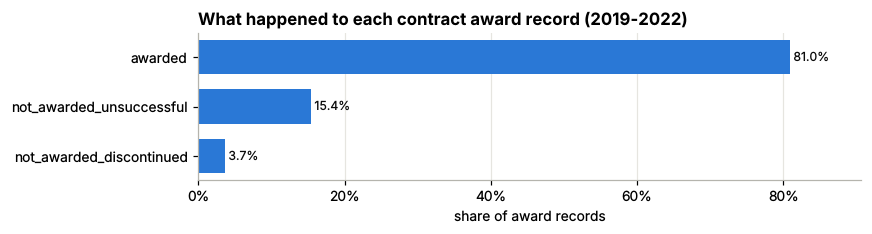

,award_status,awards,share
0,awarded,2879742,81.0%
1,not_awarded_unsuccessful,547084,15.4%
2,not_awarded_discontinued,130332,3.7%


In [15]:
status = query("""
    SELECT award_status, COUNT(*) AS awards, COUNT(*) / SUM(COUNT(*)) OVER () AS share
    FROM ted_awards
    GROUP BY award_status
    ORDER BY awards DESC
""")
bar_chart(status, "award_status", "share", "What happened to each contract award record (2019-2022)",
          "share of award records", percent=True)
as_percent(status, ["share"])

**Finding.** The 33 countries are present every year. The number of awards grew from 798,690 (2019) to 948,152 (2022). 81.0% of records were awarded, 15.4% were unsuccessful (no valid offer) and 3.7% discontinued. The awarded share fell from 84.6% in 2019 to 79.4%-80.4% in 2020-2022: some tenders attract no acceptable offer at all, which is a finding in its own right.

## 3. Why is the number of offers missing?

Before using `number_offers` as the ML target, every missing value in the raw data is traced to a reason.

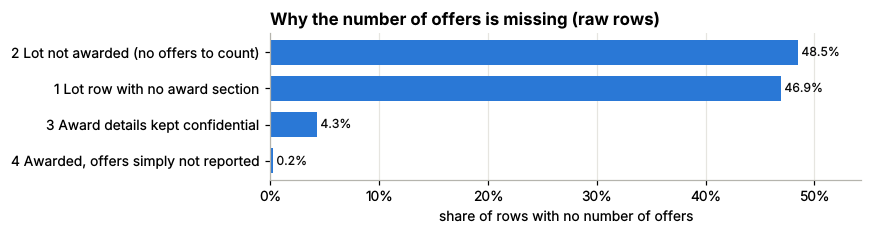

,reason,raw_rows,share_of_missing
0,1 Lot row with no award section,667385,46.9%
1,2 Lot not awarded (no offers to count),689219,48.5%
2,3 Award details kept confidential,61655,4.3%
3,"4 Awarded, offers simply not reported",3302,0.2%
4,TOTAL,1421561,100.0%


In [16]:
# Start from the RAW data (4.3M rows) and explain every missing number of offers.
missing_offers = query("""
    SELECT
        CASE
            WHEN id_award IS NULL THEN '1 Lot row with no award section'
            WHEN info_on_non_award IS NOT NULL THEN '2 Lot not awarded (no offers to count)'
            WHEN info_unpublished = 'Y' THEN '3 Award details kept confidential'
            ELSE '4 Awarded, offers simply not reported'
        END AS reason,
        COUNT(*) AS raw_rows
    FROM raw_ted_awards
    WHERE number_offers IS NULL OR TRIM(number_offers) = ''
    GROUP BY reason
    ORDER BY reason
""")
missing_offers["share_of_missing"] = missing_offers["raw_rows"] / missing_offers["raw_rows"].sum()
bar_chart(missing_offers, "reason", "share_of_missing", "Why the number of offers is missing (raw rows)",
          "share of rows with no number of offers", percent=True)
total_row = pd.DataFrame([{"reason": "TOTAL", "raw_rows": missing_offers["raw_rows"].sum(), "share_of_missing": 1.0}])
as_percent(pd.concat([missing_offers, total_row], ignore_index=True), ["share_of_missing"])

**Finding.** All 1,421,561 raw rows without an offer count are explained:
- **46.9%** are lot rows with no award section (the CSV lists lots and awards on separate rows; TED codebook §3.7).
- **48.5%** are lots that were never awarded, so there were no offers to count.
- **4.3%** are awards whose details the buyer kept confidential.
- **0.2% (3,302 rows)** are awarded contracts that simply omit it.

**Implication:** the target is missing for structural reasons, not at random among awarded contracts.

## 4. How many offers do contracts receive?

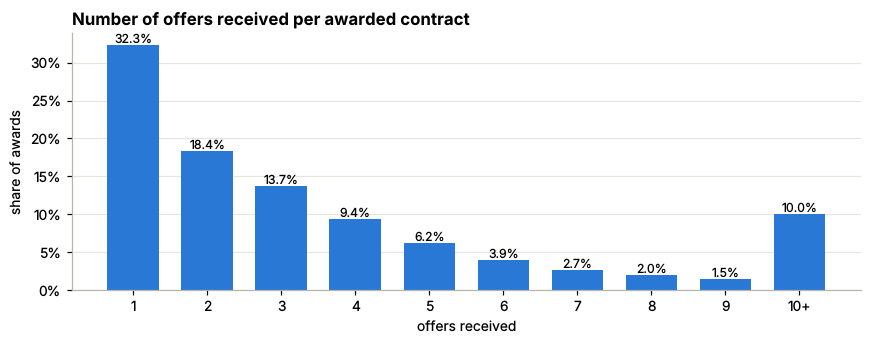

,offers,awards,share
0,1,909084,32.3%
1,2,516593,18.4%
2,3,385871,13.7%
3,4,264897,9.4%
4,5,174400,6.2%
5,6,110821,3.9%
6,7,75040,2.7%
7,8,55887,2.0%
8,9,41128,1.5%
9,10+,280597,10.0%


In [17]:
offers = query("""
    SELECT
        CASE WHEN number_offers >= 10 THEN '10+' ELSE CAST(number_offers AS VARCHAR) END AS offers,
        COUNT(*) AS awards
    FROM ted_awards
    WHERE award_status = 'awarded' AND number_offers IS NOT NULL
    GROUP BY 1
""")
offers["sort_key"] = offers["offers"].str.replace("+", "", regex=False).astype(int)
offers = offers.sort_values("sort_key").drop(columns="sort_key").reset_index(drop=True)
offers["share"] = offers["awards"] / offers["awards"].sum()

figure, axis = plt.subplots(figsize=(8, 3.2))
bars = axis.bar(offers["offers"], offers["share"], color=BAR_COLOUR, width=0.7)
for bar, share in zip(bars, offers["share"]):
    axis.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{share:.1%}",
              ha="center", va="bottom", fontsize=8)
axis.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
axis.grid(axis="x", visible=False)
axis.set_title("Number of offers received per awarded contract", loc="left")
axis.set_xlabel("offers received")
axis.set_ylabel("share of awards")
plt.tight_layout()
plt.show()
as_percent(offers, ["share"])

**Finding.** 32.3% of awards received exactly 1 offer, 18.4% received 2, 13.7% received 3, and 10.0% received 10 or more. One offer is the single most common outcome.

In [18]:
label_summary = query("""
    SELECT
        COUNT(*) FILTER (WHERE award_status = 'awarded')  AS awarded_contracts,
        COUNT(*) FILTER (WHERE is_single_bid IS NOT NULL) AS labelled_awards,
        COUNT(*) FILTER (WHERE is_single_bid IS NOT NULL)
          / COUNT(*) FILTER (WHERE award_status = 'awarded') AS labelled_share_of_awarded,
        COUNT(*) FILTER (WHERE is_single_bid = 1)         AS single_bid_awards,
        AVG(is_single_bid)                                AS single_bid_rate
    FROM ted_awards
""")
OVERALL_RATE = label_summary["single_bid_rate"].iloc[0]
as_percent(label_summary, ["labelled_share_of_awarded", "single_bid_rate"])

,awarded_contracts,labelled_awards,labelled_share_of_awarded,single_bid_awards,single_bid_rate
0,2879742,2814318,97.7%,909084,32.3%


**Finding.** 2,814,318 of the 2,879,742 awarded contracts (97.7%) have a valid label, of which 909,084 are single-bid (32.3%). For the classifier this is about one positive for every two negatives: imbalanced enough to judge the model on precision and recall rather than accuracy, but not extreme.

## 5. Where is single bidding most common?

Single-bid rate = share of labelled awards that received exactly one offer. Groups with too few awards are hidden because their rates are unstable. These are associations, not causes.

In [19]:
def single_bid_rate_by(column, minimum_awards=1000, where="TRUE"):
    """Single-bid rate per value of `column`, for groups with enough labelled awards."""
    return query(f"""
        SELECT
            {column} AS grp,
            COUNT(*)            AS labelled_awards,
            AVG(is_single_bid)  AS single_bid_rate
        FROM ted_awards
        WHERE is_single_bid IS NOT NULL AND {column} IS NOT NULL AND {where}
        GROUP BY {column}
        HAVING COUNT(*) >= {minimum_awards}
        ORDER BY single_bid_rate DESC
    """)

### 5.1 By country

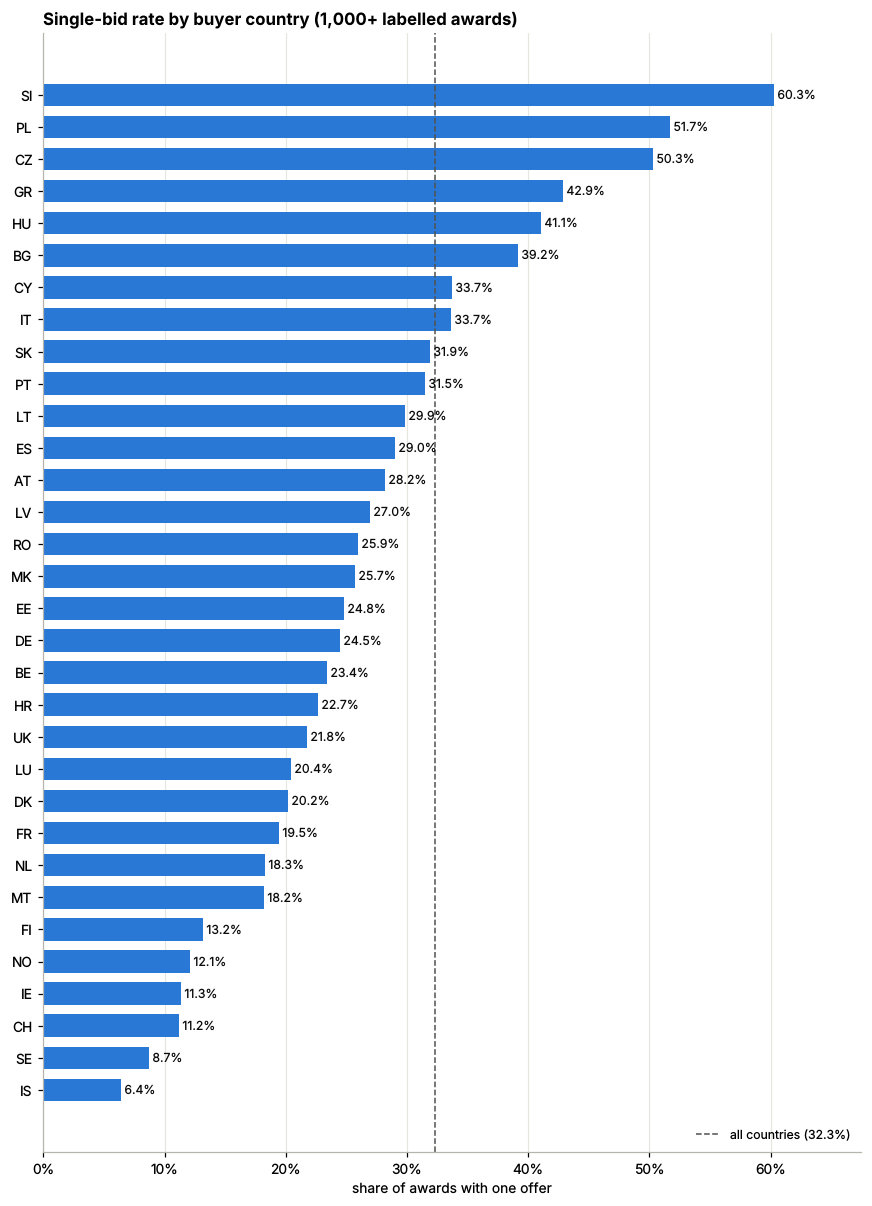

,grp,labelled_awards,single_bid_rate
0,SI,125480,60.3%
1,PL,524221,51.7%
2,CZ,115167,50.3%
3,GR,33415,42.9%
4,HU,40854,41.1%
5,BG,65596,39.2%
6,CY,2874,33.7%
7,IT,100728,33.7%
8,SK,15216,31.9%
9,PT,26009,31.5%


In [20]:
by_country = single_bid_rate_by("buyer_country")
bar_chart(by_country, "grp", "single_bid_rate", "Single-bid rate by buyer country (1,000+ labelled awards)",
          "share of awards with one offer", reference=OVERALL_RATE, reference_label="all countries", percent=True)
as_percent(by_country, ["single_bid_rate"])

**Finding.** Single-bid rates differ almost tenfold between countries: Slovenia 60.3%, Poland 51.7%, Czechia 50.3%, against Sweden 8.7% and Iceland 6.4%. France, the second-largest publisher (402,142 labelled awards), is at 19.5%.

**Caution:** countries differ in what they buy, how they split tenders into lots and which contracts they publish on TED, so this is not a ranking of integrity.

### 5.2 By procedure type

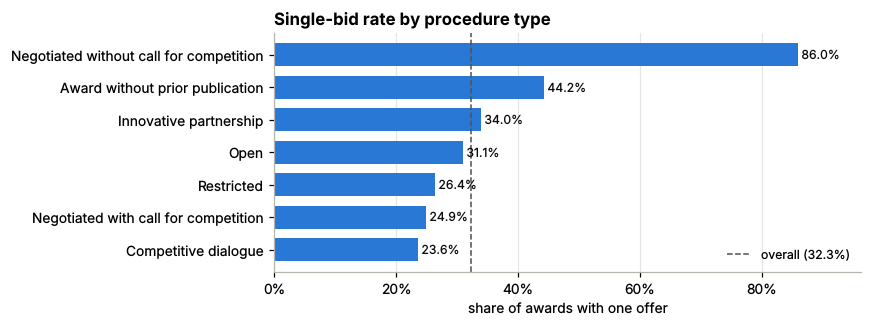

,grp,labelled_awards,single_bid_rate
0,Negotiated without call for competition,79276,86.0%
1,Award without prior publication,36117,44.2%
2,Innovative partnership,1239,34.0%
3,Open,2469524,31.1%
4,Restricted,111740,26.4%
5,Negotiated with call for competition,106353,24.9%
6,Competitive dialogue,3019,23.6%


In [21]:
by_procedure = single_bid_rate_by("procedure_type")
bar_chart(by_procedure, "grp", "single_bid_rate", "Single-bid rate by procedure type",
          "share of awards with one offer", reference=OVERALL_RATE, reference_label="overall", percent=True)
as_percent(by_procedure, ["single_bid_rate"])

In [22]:
# Competitive procedures (a public call for competition) vs non-competitive ones.
by_competitive = single_bid_rate_by("is_competitive_procedure")
as_percent(by_competitive, ["single_bid_rate"])

,grp,labelled_awards,single_bid_rate
0,False,115393,73.0%
1,True,2691875,30.6%


**Finding.** Negotiated procedures **without** a call for competition are single-bid 86.0% of the time and awards without prior publication 44.2%: these procedures do not invite open competition, so one offer is expected by design. Taken together, non-competitive procedures are 73.0% single-bid, against **30.6%** for competitive ones (open 31.1%, restricted 26.4%, negotiated with a call 24.9%, competitive dialogue 23.6%).

**Implication for Phase 5:** the useful question is *"will this competitive tender attract only one bidder?"*, so the model trains on competitive procedures.

### 5.3 By contract features

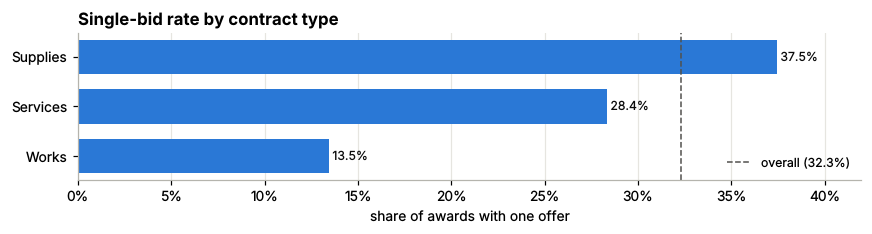

,grp,labelled_awards,single_bid_rate
0,Supplies,1596164,37.5%
1,Services,987281,28.4%
2,Works,230873,13.5%


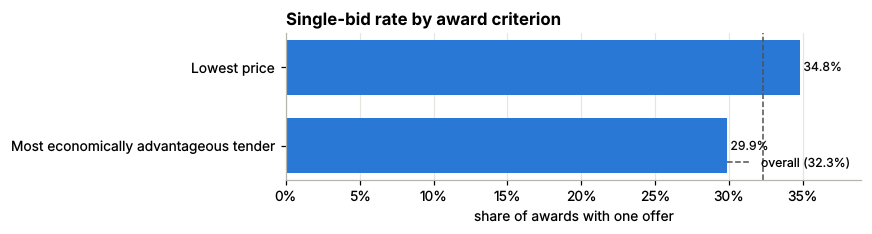

,grp,labelled_awards,single_bid_rate
0,Lowest price,1373449,34.8%
1,Most economically advantageous tender,1273460,29.9%


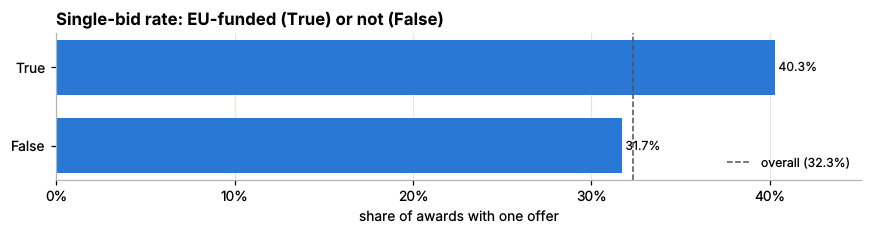

,grp,labelled_awards,single_bid_rate
0,True,185408,40.3%
1,False,2533244,31.7%


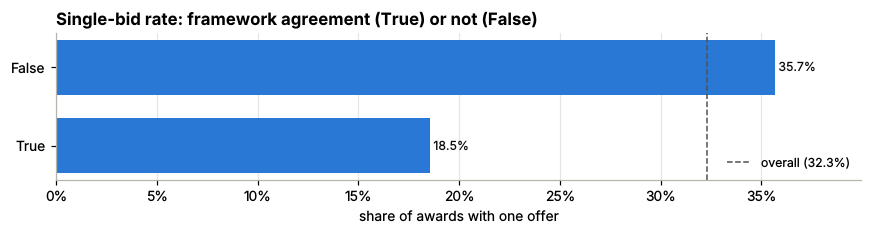

,grp,labelled_awards,single_bid_rate
0,False,2260420,35.7%
1,True,553898,18.5%


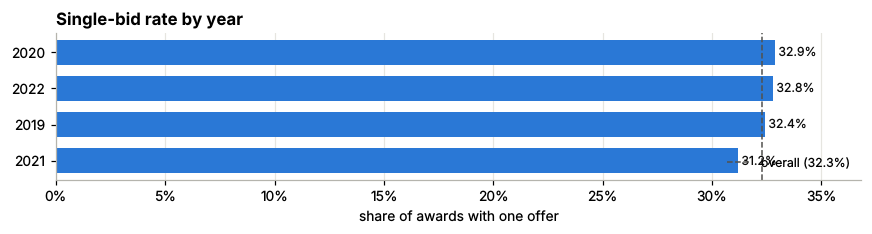

,grp,labelled_awards,single_bid_rate
2,2019,658568,32.4%
0,2020,676752,32.9%
3,2021,743401,31.2%
1,2022,735597,32.8%


In [23]:
for column, title in [
    ("contract_type", "Single-bid rate by contract type"),
    ("award_criterion", "Single-bid rate by award criterion"),
    ("is_eu_funded", "Single-bid rate: EU-funded (True) or not (False)"),
    ("is_framework_agreement", "Single-bid rate: framework agreement (True) or not (False)"),
    ("notice_year", "Single-bid rate by year"),
]:
    table = single_bid_rate_by(column)
    if column == "notice_year":
        table = table.sort_values("grp")
    bar_chart(table, "grp", "single_bid_rate", title, "share of awards with one offer",
              reference=OVERALL_RATE, reference_label="overall", percent=True)
    display(as_percent(table, ["single_bid_rate"]))

**Findings** (from the five tables above).
- **Contract type:** supplies 37.5%, services 28.4%, works 13.5%.
- **Award criterion:** lowest price 34.8% vs best value (MEAT) 29.9%.
- **EU funding:** EU-funded 40.3% vs 31.7% for others.
- **Framework agreements:** 18.5% vs 33.3% for other contracts.
- **Year:** between 31.2% and 32.9%, so no strong trend over 2019-2022.

These are associations: EU-funded contracts, for example, are concentrated in certain countries and sectors.

### 5.4 By sector

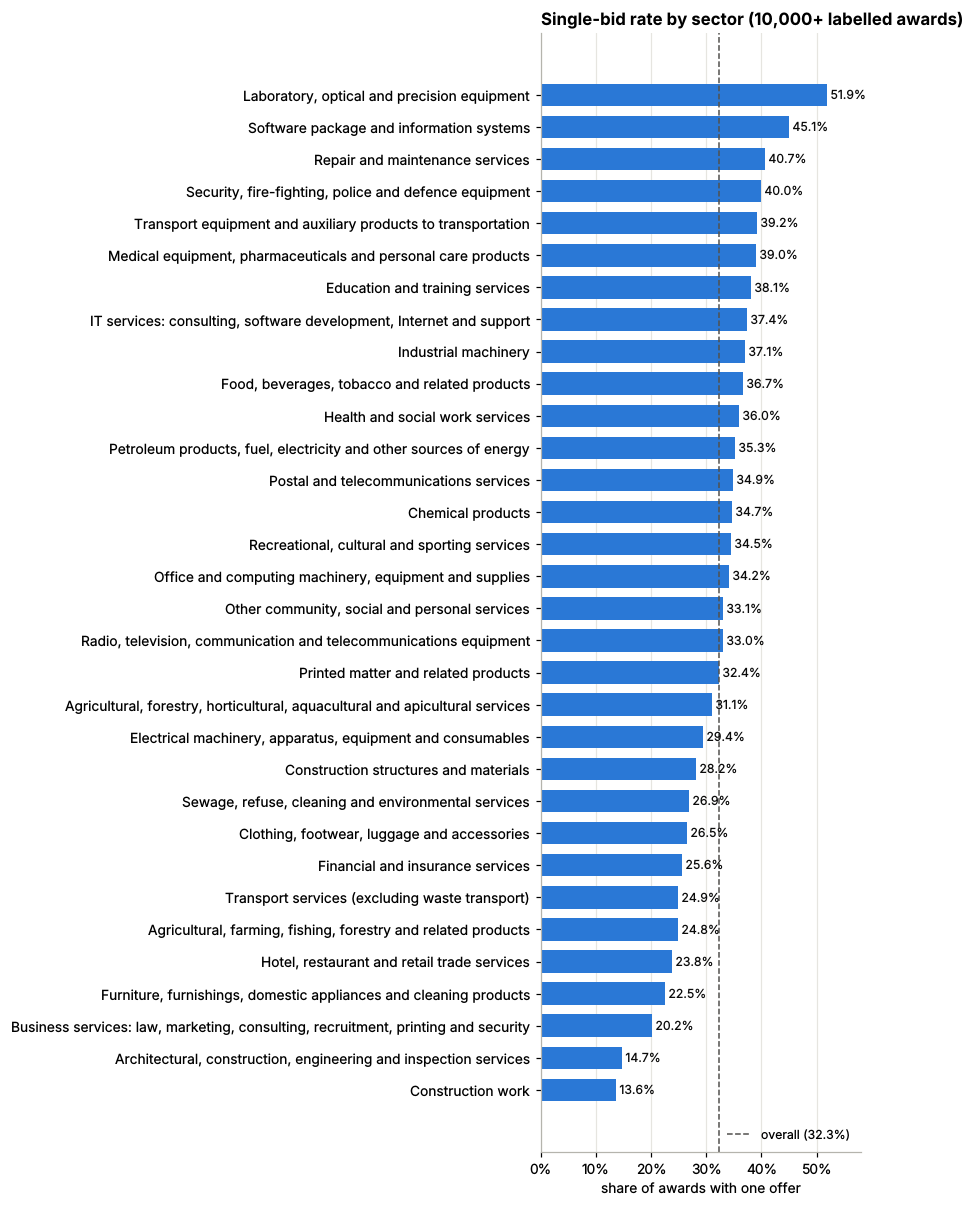

,grp,labelled_awards,single_bid_rate,share_of_labelled_awards
0,"Laboratory, optical and precision equipment",43112,51.9%,1.5%
1,Software package and information systems,24417,45.1%,0.9%
2,Repair and maintenance services,101804,40.7%,3.6%
3,"Security, fire-fighting, police and defence eq...",18768,40.0%,0.7%
4,Transport equipment and auxiliary products to ...,83710,39.2%,3.0%
5,"Medical equipment, pharmaceuticals and persona...",908396,39.0%,32.3%
6,Education and training services,54724,38.1%,1.9%
7,"IT services: consulting, software development,...",60884,37.4%,2.2%
8,Industrial machinery,20460,37.1%,0.7%
9,"Food, beverages, tobacco and related products",163710,36.7%,5.8%


In [24]:
by_sector = single_bid_rate_by("cpv_division_name", minimum_awards=10000)
by_sector["share_of_labelled_awards"] = by_sector["labelled_awards"] / label_summary["labelled_awards"].iloc[0]
bar_chart(by_sector, "grp", "single_bid_rate", "Single-bid rate by sector (10,000+ labelled awards)",
          "share of awards with one offer", reference=OVERALL_RATE, reference_label="overall", percent=True)
as_percent(by_sector, ["single_bid_rate", "share_of_labelled_awards"])

**Finding.** Specialised supplies have the highest rates: laboratory and precision equipment 51.9%, software packages 45.1%, repair and maintenance 40.7%. Construction work (13.6%) and architecture and engineering services (14.7%) are the lowest. Medical equipment and pharmaceuticals is by far the largest sector (908,396 labelled awards, 32.3% of the total) and is at 39.0%.

### 5.5 By contract value

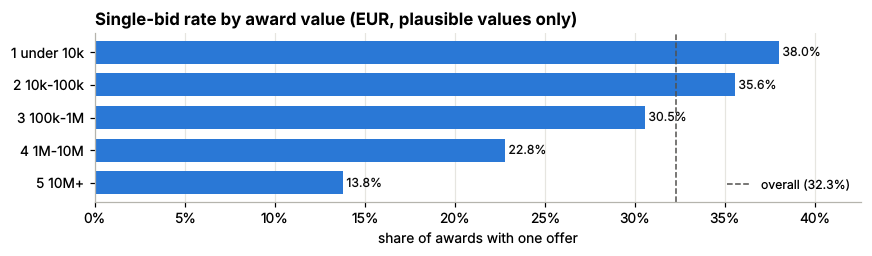

,value_band,labelled_awards,single_bid_rate
0,1 under 10k,755144,38.0%
1,2 10k-100k,720845,35.6%
2,3 100k-1M,753794,30.5%
3,4 1M-10M,247971,22.8%
4,5 10M+,59544,13.8%


In [25]:
by_value = query("""
    SELECT
        CASE
            WHEN award_value_eur < 10000      THEN '1 under 10k'
            WHEN award_value_eur < 100000     THEN '2 10k-100k'
            WHEN award_value_eur < 1000000    THEN '3 100k-1M'
            WHEN award_value_eur < 10000000   THEN '4 1M-10M'
            ELSE                                   '5 10M+'
        END AS value_band,
        COUNT(*)           AS labelled_awards,
        AVG(is_single_bid) AS single_bid_rate
    FROM ted_awards
    WHERE is_single_bid IS NOT NULL AND award_value_quality = 'plausible'
    GROUP BY value_band
    ORDER BY value_band
""")
bar_chart(by_value, "value_band", "single_bid_rate", "Single-bid rate by award value (EUR, plausible values only)",
          "share of awards with one offer", reference=OVERALL_RATE, reference_label="overall", percent=True)
as_percent(by_value, ["single_bid_rate"])

**Finding.** Single bidding falls steadily with contract size: 38.0% under EUR 10k, 35.6% for 10k-100k, 30.5% for 100k-1M, 22.8% for 1M-10M and 13.9% above EUR 10M.

**Caution for the model:** the final award value is only known after the tender. A model that predicts *before* publication must not use it (that would be data leakage).

## 6. Contract values: what is plausible?

In [26]:
value_quality = query("""
    SELECT award_value_quality, COUNT(*) AS awards, COUNT(*) / SUM(COUNT(*)) OVER () AS share
    FROM ted_awards
    WHERE award_status = 'awarded'
    GROUP BY 1
    ORDER BY awards DESC
""")
as_percent(value_quality, ["share"], decimals=2)

,award_value_quality,awards,share
0,plausible,2550372,88.56%
1,too_low,260223,9.04%
2,missing,67014,2.33%
3,too_high,1486,0.05%
4,placeholder,647,0.02%


In [27]:
# Where do the implausibly low values (< 100 EUR) come from?
too_low = query("""
    SELECT
        buyer_country,
        COUNT(*) FILTER (WHERE award_value_quality = 'too_low') AS too_low_awards,
        AVG(CASE WHEN award_value_quality = 'too_low' THEN 1.0 ELSE 0.0 END) AS too_low_share_of_country,
        AVG(CASE WHEN award_value_quality = 'too_low' AND is_framework_agreement THEN 1.0
                 WHEN award_value_quality = 'too_low' THEN 0.0 END) AS framework_share_of_too_low
    FROM ted_awards
    WHERE award_status = 'awarded'
    GROUP BY buyer_country
    ORDER BY too_low_awards DESC
    LIMIT 8
""")
as_percent(too_low, ["too_low_share_of_country", "framework_share_of_too_low"])

,buyer_country,too_low_awards,too_low_share_of_country,framework_share_of_too_low
0,DE,120075,39.5%,37.9%
1,RO,29527,8.2%,0.0%
2,NL,17384,44.3%,36.7%
3,PL,16150,3.1%,0.5%
4,FR,15207,3.6%,75.6%
5,UK,13532,14.9%,32.0%
6,ES,10410,6.2%,17.9%
7,SE,7520,9.9%,24.9%


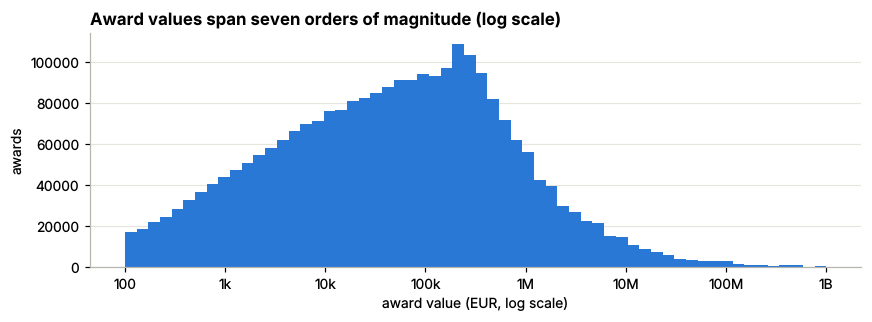

,p25,median,p75,mean
0,"6,385.48","54,300.00","315,731.44","2,078,226.85"


In [28]:
values = query("""
    SELECT LOG10(award_value_eur) AS log_value
    FROM ted_awards
    WHERE award_status = 'awarded' AND award_value_quality = 'plausible'
""")
figure, axis = plt.subplots(figsize=(8, 3))
axis.hist(values["log_value"], bins=60, color=BAR_COLOUR)
axis.set_xticks(range(2, 10))
axis.set_xticklabels(["100", "1k", "10k", "100k", "1M", "10M", "100M", "1B"])
axis.grid(axis="x", visible=False)
axis.set_title("Award values span seven orders of magnitude (log scale)", loc="left")
axis.set_xlabel("award value (EUR, log scale)")
axis.set_ylabel("awards")
plt.tight_layout()
plt.show()
query("""
    SELECT
        QUANTILE_CONT(award_value_eur, 0.25) AS p25,
        MEDIAN(award_value_eur)              AS median,
        QUANTILE_CONT(award_value_eur, 0.75) AS p75,
        AVG(award_value_eur)                 AS mean
    FROM ted_awards
    WHERE award_status = 'awarded' AND award_value_quality = 'plausible'
""")

**Findings.**
- 88.56% of awarded contracts have a plausible value, 9.04% are below EUR 100 (`too_low`), 2.33% are missing, 0.05% are EUR 1 billion or more (`too_high`) and 0.02% are placeholders made only of 9s (`placeholder`, e.g. 999,999,999).
- `too_low` values are concentrated: 120,075 in Germany (39.5% of German awards) and 44.3% of Dutch awards. In France, 75.6% of them are framework agreements, where the published value is often symbolic. They are **flagged, not deleted**.
- Plausible values are very skewed: median EUR 54,300 vs mean EUR 2,078,227, so this analysis uses medians and a log scale.

## 7. Vendor names: how messy, and how much does standardisation help?

In [29]:
# How many different raw spellings map to the key 'siemens healthcare'?
siemens = query("""
    SELECT winner_name, COUNT(*) AS awards
    FROM ted_awards
    WHERE winner_name_std = 'siemens healthcare'
    GROUP BY winner_name
    ORDER BY awards DESC
""")
print(f"{len(siemens)} different raw spellings map to 'siemens healthcare'. The 10 most frequent:")
siemens.head(10)

124 different raw spellings map to 'siemens healthcare'. The 10 most frequent:


,winner_name,awards
0,Siemens Healthcare Sp. z o.o.,494
1,Siemens Healthcare GmbH,422
2,SIEMENS HEALTHCARE SRL,284
3,"Siemens Healthcare, s.r.o.",234
4,"SIEMENS HEALTHCARE, S.L.U.",118
5,"Siemens Healthcare, S. L. U.",105
6,Siemens Healthcare S.R.L.,97
7,Siemens Healthcare AB,75
8,Siemens Healthcare Sp. z o. o.,70
9,Siemens Healthcare Oy,66


In [30]:
vendor_counts = query("""
    SELECT
        COUNT(DISTINCT winner_name)     AS distinct_raw_names,
        COUNT(DISTINCT winner_name_std) AS distinct_standardised_names,
        1 - COUNT(DISTINCT winner_name_std) / COUNT(DISTINCT winner_name) AS reduction
    FROM ted_awards
    WHERE award_status = 'awarded'
""")
as_percent(vendor_counts, ["reduction"])

,distinct_raw_names,distinct_standardised_names,reduction
0,720095,480403,33.3%


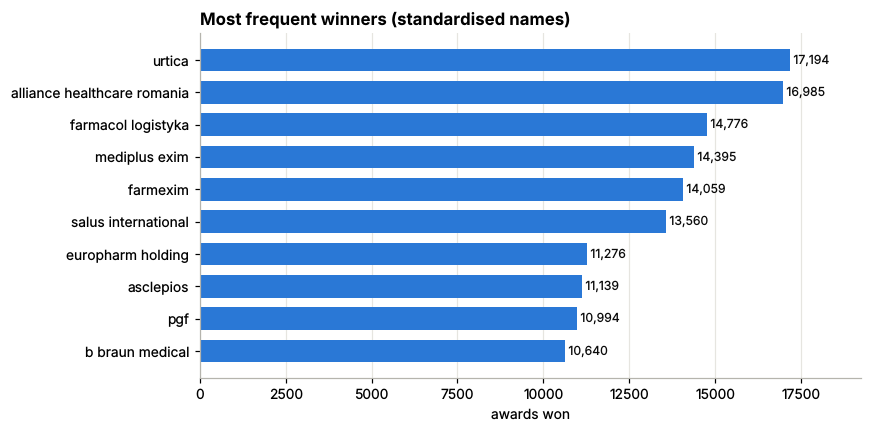

,winner_name_std,awards,buyer_countries
0,urtica,17194,1
1,alliance healthcare romania,16985,1
2,farmacol logistyka,14776,1
3,mediplus exim,14395,1
4,farmexim,14059,1
5,salus international,13560,1
6,europharm holding,11276,1
7,asclepios,11139,1
8,pgf,10994,1
9,b braun medical,10640,17


In [31]:
top_vendors = query("""
    SELECT winner_name_std, COUNT(*) AS awards, COUNT(DISTINCT buyer_country) AS buyer_countries
    FROM ted_awards
    WHERE award_status = 'awarded' AND winner_name_std IS NOT NULL
    GROUP BY 1
    ORDER BY awards DESC
    LIMIT 10
""")
bar_chart(top_vendors, "winner_name_std", "awards", "Most frequent winners (standardised names)", "awards won")
top_vendors

**Findings.**
- **124** different raw spellings map to `siemens healthcare` (legal forms, capitalisation, punctuation, country branches).
- Standardisation reduces distinct winner names from 720,095 to 480,403 (**-33.3%**).
- The most frequent winners by **number of awards** are pharmaceutical and medical distributors in Romania and Poland (all with 1 buyer country). Medical tenders are split into very many small lots, so award counts are not money won.

**Deliberate limits:** different subsidiaries (`siemens healthcare` vs `siemens`), translated names and spelling mistakes are not merged; a transparent rule is preferred to aggressive fuzzy matching.

## 8. World Bank contracts

In [32]:
wb_overview = query("""
    SELECT
        CAST(signing_year AS VARCHAR)     AS signing_year,
        COUNT(DISTINCT contract_id)       AS contracts,
        SUM(amount_usd_for_totals) / 1e9  AS total_usd_bn,
        COUNT(DISTINCT borrower_country)  AS borrower_countries
    FROM world_bank_awards
    GROUP BY signing_year
    UNION ALL
    SELECT 'TOTAL', COUNT(DISTINCT contract_id), SUM(amount_usd_for_totals) / 1e9,
           COUNT(DISTINCT borrower_country)
    FROM world_bank_awards
    ORDER BY signing_year
""")
wb_overview

,signing_year,contracts,total_usd_bn,borrower_countries
0,2019,15474,6.64,137
1,2020,40504,16.01,143
2,2021,40121,19.44,149
3,2022,40485,15.32,146
4,TOTAL,136584,57.41,153


In [33]:
double_count = query("""
    SELECT
        SUM(amount_usd) / 1e9            AS naive_total_usd_bn,
        SUM(amount_usd_for_totals) / 1e9 AS corrected_total_usd_bn,
        (SUM(amount_usd) - SUM(amount_usd_for_totals)) / 1e9 AS double_counted_usd_bn,
        (SUM(amount_usd) - SUM(amount_usd_for_totals)) / SUM(amount_usd_for_totals) AS overstatement
    FROM world_bank_awards
""")
as_percent(double_count, ["overstatement"])

,naive_total_usd_bn,corrected_total_usd_bn,double_counted_usd_bn,overstatement
0,61.83,57.41,4.42,7.7%


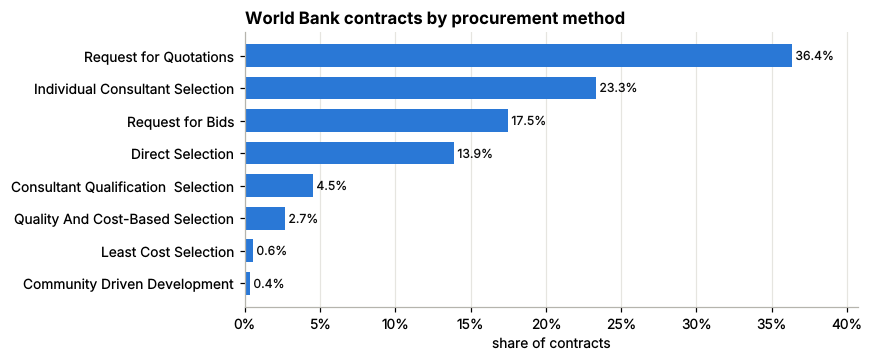

,procurement_method,contracts,share
0,Request for Quotations,49678,36.4%
1,Individual Consultant Selection,31822,23.3%
2,Request for Bids,23886,17.5%
3,Direct Selection,19020,13.9%
4,Consultant Qualification Selection,6204,4.5%
5,Quality And Cost-Based Selection,3649,2.7%
6,Least Cost Selection,776,0.6%
7,Community Driven Development,484,0.4%


In [34]:
wb_methods = query("""
    SELECT procurement_method, COUNT(DISTINCT contract_id) AS contracts
    FROM world_bank_awards
    GROUP BY 1
    ORDER BY contracts DESC
    LIMIT 8
""")
wb_methods["share"] = wb_methods["contracts"] / query(
    "SELECT COUNT(DISTINCT contract_id) AS n FROM world_bank_awards")["n"].iloc[0]
bar_chart(wb_methods, "procurement_method", "share", "World Bank contracts by procurement method",
          "share of contracts", percent=True)
as_percent(wb_methods, ["share"])

**Findings.**
- 136,584 contracts worth USD 57.41 bn in 153 borrower countries. 2019 is partial (15,474 contracts) because the source starts at fiscal year 2020 (July 2019).
- A naive sum gives USD 61.83 bn: joint ventures repeat the full amount per partner, so USD 4.42 bn would be double counted, a **7.7% overstatement**. `amount_usd_for_totals` corrects it.
- Request for quotations (36.4%) and individual consultant selection (23.3%) are the most common methods; direct selection, a non-competitive method, is 13.9%.

## 9. Linking the two sources

The sources describe different markets (EU public buyers vs World Bank-financed projects), so there is no shared contract ID. The link is the **company**: the same standardised name from the same country.

In [35]:
# Companies that appear in BOTH sources: same standardised name AND same country.
both_sources = query("""
    WITH eu_winners AS (
        SELECT winner_name_std AS name_std, winner_country AS country, COUNT(*) AS eu_awards
        FROM ted_awards
        WHERE award_status = 'awarded' AND winner_name_std IS NOT NULL
        GROUP BY 1, 2
    ),
    world_bank_suppliers AS (
        SELECT supplier_name_std AS name_std, supplier_country_code AS country,
               COUNT(DISTINCT contract_id) AS world_bank_contracts
        FROM world_bank_awards
        WHERE supplier_name_std IS NOT NULL
        GROUP BY 1, 2
    )
    SELECT name_std, country, eu_awards, world_bank_contracts
    FROM eu_winners
    INNER JOIN world_bank_suppliers USING (name_std, country)
    ORDER BY world_bank_contracts DESC
""")
print(f"{len(both_sources):,} companies won EU tenders and World Bank contracts (2019-2022)")
both_sources.head(10)

672 companies won EU tenders and World Bank contracts (2019-2022)


,name_std,country,eu_awards,world_bank_contracts
0,sinohydro,CN,3,41
1,sofreco,FR,3,32
2,artelia,FR,447,20
3,eptisa servicios de ingenieria,ES,26,17
4,china meheco,CN,7,13
5,deloitte touche tohmatsu india,IN,1,12
6,ge medical systems,FR,119,12
7,sd biosensor,KR,3,10
8,eta2u,RO,170,10
9,coba consultores de engenharia e ambiente,PT,18,10


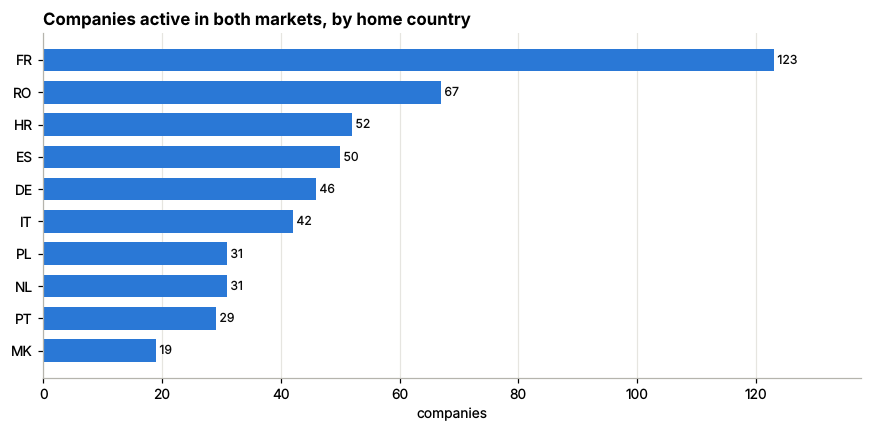

,country,companies
20,FR,123
49,RO,67
23,HR,52
18,ES,50
16,DE,46
29,IT,42
43,NL,31
47,PL,31
48,PT,29
39,MK,19


In [36]:
link_countries = both_sources.groupby("country").size().reset_index(name="companies")
link_countries = link_countries.sort_values("companies", ascending=False).head(10)
bar_chart(link_countries, "country", "companies", "Companies active in both markets, by home country", "companies")
link_countries

**Finding.** 672 companies won both EU tenders and World Bank contracts. Examples above: Artelia (FR) with 447 EU awards and 20 World Bank contracts, GE Medical Systems (FR) 119 and 12. France has the most such companies (123), then Romania (67) and Croatia (52).

**How the join works:** each side is first grouped to one row per company, then joined on `(name_std, country)`. Requiring the same country avoids merging unrelated companies with similar names. Exact matching gives a conservative lower bound.

## 10. Conclusions and decisions for the next phases

| Finding (section) | Decision |
|---|---|
| 97.7% of awarded contracts have a valid label (4) | `is_single_bid` is the ML target |
| Non-competitive procedures are single-bid by design (5.2) | Phase 5 trains on competitive procedures only |
| The final award value is only known after the tender (5.5) | Not used as a model feature (leakage) |
| `estimated_value_eur` missing for 59.2% (1.5) | Use with a missing-value indicator, or not at all |
| 9.04% implausibly low values, very skewed values (6) | Value analysis uses `award_value_quality = 'plausible'`, medians, log scale |
| Award counts are not money (7) | Phase 3 measures vendor concentration by value and by count |
| The sources connect through companies (9) | Phase 3 builds a vendor dimension on `(name_std, country)` |

In [37]:
connection.close()